# B0 — Nettoyage audio : langue, parole et transcriptions

Projet Données Multimédia — M2 SID 2026 · partie **audio** (Ghislain).

Certains extraits ne sont pas en anglais et d'autres ne contiennent **aucune parole** (musique, bruitages) : sur ces extraits, Whisper invente souvent du texte (« hallucinations »). Ce notebook :
1. analyse chaque audio avec **Whisper small** (`faster-whisper`) : durée de parole (VAD) et langue parlée ;
2. classe chaque extrait en `anglais`, `autre_langue`, `sans_parole` ou `incertain` ;
3. analyse la répartition par film, par émotion et par ensemble (partition officielle du groupe) ;
4. nettoie les transcriptions du groupe (`transcriptions_audio.csv`) en ne gardant que celles qui sont fiables.

**On ne supprime aucun fichier et on ne modifie pas la partition.** Les résultats servent de *filtre* pour les autres notebooks.

**Résultats** (dans `Partie audio/ghislain/` sur le Drive) :
- `langues.csv` : statut, langue et durée de parole de chaque extrait ;
- `transcriptions_nettoyees.csv` : transcriptions + colonne `transcription_fiable` ;
- `audio_statut_langue.png` : figure de synthèse.

**Exécution sur Colab** : *Exécution → Modifier le type d'exécution → T4 GPU*, puis *Tout exécuter*. Le calcul est **reprenable** : si la session coupe, relancer reprend là où il s'était arrêté.

> Prérequis Drive : le dossier partagé **« Projet Multimédia »** doit apparaître dans *Mon Drive*. Sinon : clic droit sur le dossier dans *Partagés avec moi* → *Organiser* → *Ajouter un raccourci* → *Mon Drive*.

## 0. Installation, données et chemins

In [4]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
ZIP_ID = "1ykUsEsbMoMlsji4eewSPVgUgqjT98GJH"   # PROJET_SID_2026.zip sur le Drive du groupe

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    # av<16 : les versions récentes de PyAV sont incompatibles avec faster-whisper 1.2
    # cuBLAS / cuDNN (CUDA 12) : nécessaires à faster-whisper sur GPU, absents de l'image Colab actuelle
    !pip install -q faster-whisper "av<16" gdown nvidia-cublas-cu12 "nvidia-cudnn-cu12==9.*"

    PROJET = Path("/content/drive/MyDrive/Projet Multimédia")
    assert PROJET.exists(), ("Dossier 'Projet Multimédia' introuvable dans Mon Drive : "
                             "ajoutez un raccourci (voir l'introduction).")
    SPLITS_DIR = PROJET / "Repartition_Splits" / "Répartition"
    TRANSCRIPTIONS = PROJET / "Partie audio" / "transcriptions_audio.csv"
    OUT = PROJET / "Partie audio" / "ghislain"

    # Données : même convention que le reste du groupe (/content/data/PROJET_SID_2026/movie)
    DATA = Path("/content/data/PROJET_SID_2026")
    if not (DATA / "movie" / "audio").exists():
        ZIP_DRIVE = PROJET / "PROJET_SID_2026.zip"
        if ZIP_DRIVE.exists():
            # Copie depuis le Drive monté : pas besoin de lien public (plus fiable que gdown)
            print("Copie du zip depuis le Drive (~2-3 min)...")
            !cp "{ZIP_DRIVE}" /content/PROJET_SID_2026.zip
        else:
            !gdown --fuzzy "https://drive.google.com/file/d/{ZIP_ID}/view" -O /content/PROJET_SID_2026.zip
        print("Décompression...")
        !mkdir -p /content/data && unzip -q -o /content/PROJET_SID_2026.zip -d /content/data
        !rm -f /content/PROJET_SID_2026.zip
else:
    # En local : dossier du projet (celui qui contient movie/ et splits/)
    DATA = next(p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / "movie").exists() and (p / "splits").exists())
    SPLITS_DIR = DATA / "splits"
    TRANSCRIPTIONS = DATA / "data_drive" / "transcriptions_audio.csv"
    OUT = DATA / "audio" / "ghislain"

OUT.mkdir(parents=True, exist_ok=True)
assert (DATA / "movie" / "audio").exists(), f"Audios introuvables sous {DATA}"
print("Données :", DATA, "\nRésultats :", OUT)

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 21.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.6/39.6 MB 31.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.3/40.3 MB 15.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 63.7 MB/s eta 0:00:00
Copie du zip depuis le Drive (~2-3 min)...
Décompression...
Données : /content/data/PROJET_SID_2026 
Résultats : /content/drive/MyDrive/Projet Multimédia/Partie audio/ghislain


In [5]:
import json
import warnings
warnings.filterwarnings("ignore")

import ctranslate2
import matplotlib.pyplot as plt
import pandas as pd
from faster_whisper import WhisperModel
from tqdm.auto import tqdm

EMOTIONS = ["amusement", "awe", "contentment", "excitement",
            "anger", "disgust", "fear", "sadness"]
MODEL_SIZE = "small"        # même taille que la transcription du groupe
MIN_PAROLE = 1.0            # secondes de parole en dessous desquelles l'extrait est "sans_parole"
MIN_PROBA = 0.5             # confiance minimale pour accepter la langue détectée


def lire_liste(split):
    # Drive : train.txt ; local : train_films.txt (même contenu)
    for nom in (f"{split}.txt", f"{split}_films.txt"):
        if (SPLITS_DIR / nom).exists():
            return (SPLITS_DIR / nom).read_text().split()
    raise FileNotFoundError(f"liste {split} introuvable dans {SPLITS_DIR}")


film2split = {f: s for s in ("train", "dev", "test") for f in lire_liste(s)}

rows = []
for f in sorted((DATA / "movie" / "annotation").glob("*/*.json")):
    a = json.loads(f.read_text(encoding="utf-8"))
    rows.append({"video_id": a["video_id"], "film_id": f.parent.name, "emotion": a["emotion"],
                 "audio": DATA / "movie" / "audio" / f.parent.name / f"{a['video_id']}.mp3"})
meta = pd.DataFrame(rows)
meta["split"] = meta.film_id.map(film2split)
assert meta.split.notna().all(), "Des films ne sont dans aucune liste train/dev/test"
print(f"{len(meta)} extraits, {meta.film_id.nunique()} films")
print(meta.groupby("split").agg(films=("film_id", "nunique"), extraits=("video_id", "size")))

3088 extraits, 350 films
       films  extraits
split                 
dev       50       442
test      50       439
train    250      2207


## 1. Détection de la parole et de la langue (reprenable)

In [3]:
def charger_libs_cuda():
    # faster-whisper (CTranslate2) cherche libcublas.so.12 / libcudnn*.so.9 au niveau système.
    # Sur Colab, elles sont installées par pip dans site-packages/nvidia/... : on les précharge.
    import ctypes, glob, site
    libs = [so for d in site.getsitepackages() for pkg in ("cublas", "cudnn")
            for so in sorted(glob.glob(f"{d}/nvidia/{pkg}/lib/lib*.so*"))]
    for _ in range(2):                         # 2 passes : certaines libs dépendent des autres
        for so in libs:
            try:
                ctypes.CDLL(so, mode=ctypes.RTLD_GLOBAL)
            except OSError:
                pass


def analyse(path):
    # transcribe() est paresseux : sans itérer sur les segments, seules la VAD
    # et la détection de langue (sur la parole uniquement) sont calculées.
    _, info = model.transcribe(str(path), vad_filter=True)
    top = sorted(info.all_language_probs or [], key=lambda x: -x[1])[:3]
    return {
        "duree": round(info.duration, 2),
        "duree_parole": round(info.duration_after_vad, 2),
        "langue": info.language,
        "proba_langue": round(info.language_probability, 3),
        "top3": " ".join(f"{l}:{p:.2f}" for l, p in top),
    }


GPU = ctranslate2.get_cuda_device_count() > 0
if GPU:
    charger_libs_cuda()
    model = WhisperModel(MODEL_SIZE, device="cuda", compute_type="float16")
else:
    model = WhisperModel(MODEL_SIZE, device="cpu", compute_type="int8")

# Test sur un fichier AVANT la boucle : si le GPU ne marche pas, on bascule sur le CPU
# au lieu d'enregistrer 3 088 erreurs.
try:
    print("Test :", analyse(meta.audio.iloc[0]))
except Exception as e:
    if not GPU:
        raise
    print(f"GPU inutilisable ({e}) -> bascule sur CPU (beaucoup plus lent)")
    GPU = False
    model = WhisperModel(MODEL_SIZE, device="cpu", compute_type="int8")
    print("Test :", analyse(meta.audio.iloc[0]))
print("Calcul sur", "GPU" if GPU else "CPU (lent : ~2-3 s par extrait)")

CSV = OUT / "langues_brut.csv"
# Les extraits déjà en "erreur" sont recalculés
done = (set(pd.read_csv(CSV).query("langue != 'erreur'").video_id)
        if CSV.exists() else set())
todo = meta[~meta.video_id.isin(done)]
print(f"{len(done)} déjà traités, {len(todo)} restants")

buffer = []
n_err = 0
for row in tqdm(todo.itertuples(), total=len(todo)):
    try:
        res = analyse(row.audio)
    except Exception as e:                     # fichier illisible : on le note
        res = {"duree": None, "duree_parole": None, "langue": "erreur",
               "proba_langue": 0.0, "top3": str(e)[:80]}
        n_err += 1
        if n_err == 20:
            raise RuntimeError(f"20 erreurs, calcul arrêté. Dernière erreur : {e}")
    buffer.append({"video_id": row.video_id, **res})
    if len(buffer) >= 50:                      # sauvegarde régulière sur le Drive
        pd.DataFrame(buffer).to_csv(CSV, mode="a", header=not CSV.exists(), index=False)
        buffer = []
if buffer:
    pd.DataFrame(buffer).to_csv(CSV, mode="a", header=not CSV.exists(), index=False)

Test : {'duree': 5.0, 'duree_parole': 4.83, 'langue': 'en', 'proba_langue': 0.996, 'top3': 'en:1.00 nn:0.00 es:0.00'}
Calcul sur CPU (lent : ~2-3 s par extrait)
0 déjà traités, 3088 restants


  0%|          | 0/3088 [00:00<?, ?it/s]

**Interprétation :** Whisper (`small`) a analysé chaque extrait. Pour chacun, on obtient la durée de parole détectée par la VAD (détection d'activité vocale), la langue parlée et la confiance du modèle. La ligne « Test » vérifie que le modèle fonctionne avant de lancer la boucle complète. Les résultats bruts sont enregistrés au fur et à mesure dans `langues_brut.csv`.

## 2. Classement des extraits

In [4]:
raw = pd.read_csv(CSV).drop_duplicates("video_id", keep="last")
df = meta.drop(columns="audio").merge(raw, on="video_id")
assert len(df) == len(meta), "Tous les extraits n'ont pas été traités : relancer la section 1"


def statut(r):
    if r.langue == "erreur":
        return "erreur"
    if r.duree_parole < MIN_PAROLE:
        return "sans_parole"
    if r.proba_langue < MIN_PROBA:
        return "incertain"
    return "anglais" if r.langue == "en" else "autre_langue"


df["statut"] = df.apply(statut, axis=1)
df["part_parole"] = (df.duree_parole / df.duree).round(3)
display(df.statut.value_counts().to_frame("extraits").assign(
    pourcentage=lambda d: (100 * d.extraits / len(df)).round(1)))

,extraits,pourcentage
statut,,
anglais,1898,61.5
sans_parole,986,31.9
incertain,113,3.7
autre_langue,91,2.9


In [5]:
autres = df[df.statut == "autre_langue"]
print("Langues détectées hors anglais :")
display(autres.langue.value_counts().to_frame("extraits"))
display(autres.sort_values(["langue", "video_id"])[
    ["video_id", "film_id", "emotion", "langue", "proba_langue", "duree_parole", "top3"]])

Langues détectées hors anglais :


,extraits
langue,
fr,34
cy,17
es,16
fa,10
la,6
ko,3
ps,1
el,1
nn,1


,video_id,film_id,emotion,langue,proba_langue,duree_parole,top3
576,00066_clip_005,00066,disgust,cy,0.917,3.48,cy:0.92 en:0.07 nn:0.00
1723,00209_clip_008,00209,awe,cy,0.828,5.18,cy:0.83 en:0.17 nn:0.00
1726,00209_clip_012,00209,awe,cy,0.898,11.55,cy:0.90 en:0.10 nn:0.00
1727,00209_clip_013,00209,disgust,cy,0.655,5.70,cy:0.66 en:0.31 la:0.02
1729,00209_clip_018,00209,awe,cy,0.610,3.81,cy:0.61 en:0.33 nn:0.03
...,...,...,...,...,...,...,...
2773,00344_clip_022,00344,contentment,la,0.903,4.11,la:0.90 en:0.04 it:0.02
2774,00344_clip_023,00344,amusement,la,0.570,2.67,la:0.57 en:0.20 nn:0.04
2581,00320_clip_009,00320,amusement,nl,0.504,4.58,nl:0.50 en:0.37 cy:0.07
1371,00163_clip_008,00163,anger,nn,0.504,5.97,nn:0.50 sv:0.08 en:0.06


## 3. Par film

Une langue étrangère concerne en général **tout un film** (film étranger ou doublé). On regarde la langue majoritaire de chaque film, sur ses extraits qui contiennent de la parole.

In [6]:
parle = df[df.statut.isin(["anglais", "autre_langue", "incertain"])]
par_film = (parle.groupby("film_id")
            .agg(split=("split", "first"),
                 extraits_parles=("video_id", "size"),
                 langue_majoritaire=("langue", lambda s: s.value_counts().index[0]),
                 part_anglais=("langue", lambda s: (s == "en").mean()))
            .round(2))
films_etrangers = par_film[par_film.langue_majoritaire != "en"]
print(f"{len(films_etrangers)} films majoritairement non anglophones sur {df.film_id.nunique()}")
display(films_etrangers.sort_values("part_anglais"))

15 films majoritairement non anglophones sur 350


,split,extraits_parles,langue_majoritaire,part_anglais
film_id,,,,
00078,train,2,ko,0.00
00085,train,7,fa,0.00
00095,train,7,fr,0.00
00105,train,4,es,0.00
00249,test,1,fr,0.00
00185,train,8,fr,0.00
00277,train,10,fr,0.00
00264,train,9,fr,0.00
00331,train,4,fa,0.00


## 4. Impact sur les émotions et sur les ensembles

statut,anglais,autre_langue,incertain,sans_parole
emotion,,,,
amusement,133,11,10,90
awe,161,16,13,96
contentment,259,5,13,96
excitement,271,4,5,74
anger,477,19,21,160
disgust,214,21,8,54
fear,178,7,29,305
sadness,205,8,14,111


statut,anglais,autre_langue,incertain,sans_parole
emotion,,,,
amusement,54.5,4.5,4.1,36.9
awe,56.3,5.6,4.5,33.6
contentment,69.4,1.3,3.5,25.7
excitement,76.6,1.1,1.4,20.9
anger,70.5,2.8,3.1,23.6
disgust,72.1,7.1,2.7,18.2
fear,34.3,1.3,5.6,58.8
sadness,60.7,2.4,4.1,32.8


statut,anglais,autre_langue,incertain,sans_parole,All
split,,,,,
train,1366,73,85,683,2207
dev,271,11,16,144,442
test,261,7,12,159,439
All,1898,91,113,986,3088


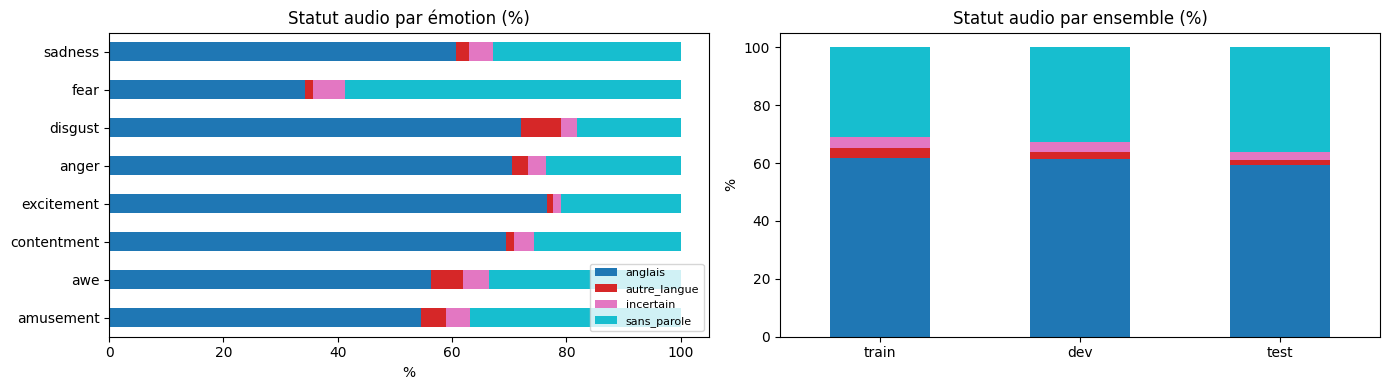

In [7]:
tab = pd.crosstab(df.emotion, df.statut).reindex(EMOTIONS)
display(tab)
display((100 * tab.div(tab.sum(axis=1), axis=0)).round(1))
display(pd.crosstab(df.split, df.statut, margins=True).loc[["train", "dev", "test", "All"]])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
(100 * tab.div(tab.sum(axis=1), axis=0)).plot.barh(stacked=True, ax=axes[0], colormap="tab10")
axes[0].set(title="Statut audio par émotion (%)", xlabel="%", ylabel="")
axes[0].legend(fontsize=8, loc="lower right")
pd.crosstab(df.split, df.statut, normalize="index").loc[["train", "dev", "test"]].mul(100).plot.bar(
    stacked=True, ax=axes[1], colormap="tab10", legend=False)
axes[1].set(title="Statut audio par ensemble (%)", ylabel="%", xlabel="")
axes[1].tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(OUT / "audio_statut_langue.png", dpi=150)

**Interprétation par émotion :**
- **`fear` est sans parole dans 58,8 % des cas**, avec en moyenne seulement 2,1 s de voix par extrait. La peur s'exprime surtout par la musique, les cris et les bruitages.
- À l'inverse, `excitement` (20,9 % sans parole), `disgust` (18,2 %) et `anger` (23,6 %) passent davantage par la voix.
- `amusement` et `awe` sont intermédiaires, autour de 35 % sans parole.

**Interprétation par ensemble :** la part d'extraits sans parole est proche dans les trois ensembles (train 30,9 %, dev 32,6 %, test 36,2 %). Le test en contient un peu plus, donc les modèles de parole et de texte y obtiendront probablement des scores légèrement plus faibles.

**Conclusion :** chaque modalité audio a sa zone de force. Les modèles de parole devraient bien reconnaître `anger` ou `excitement`, et les modèles de sons généraux `fear`. Cela justifie de **fusionner** les deux familles de modèles.

## 5. Nettoyage des transcriptions du groupe

Les transcriptions (`Partie audio/transcriptions_audio.csv`, Whisper small sans langue imposée) ne sont fiables que si l'extrait contient de la parole **en anglais**. Sur les extraits `sans_parole`, le texte est le plus souvent une hallucination.

In [8]:
tr = pd.read_csv(TRANSCRIPTIONS)[["video_id", "transcription"]]
tr["transcription"] = tr.transcription.fillna("").astype(str).str.strip()
tr = df[["video_id", "film_id", "split", "emotion", "statut", "langue", "duree_parole"]].merge(
    tr, on="video_id", how="left")
tr["transcription"] = tr.transcription.fillna("")
tr["transcription_fiable"] = tr.transcription.where(
    (tr.statut == "anglais") & (tr.transcription != ""), "")

print("Transcriptions non vides par statut :")
display(pd.crosstab(tr.statut, tr.transcription != "", margins=True)
        .rename(columns={True: "non vide", False: "vide"}))
print(f"Transcriptions fiables : {(tr.transcription_fiable != '').sum()} / {len(tr)}")

Transcriptions non vides par statut :


transcription,vide,non vide,All
statut,,,
anglais,12,1886,1898
autre_langue,1,90,91
incertain,34,79,113
sans_parole,624,362,986
All,671,2417,3088


Transcriptions fiables : 1886 / 3088


In [9]:
print("Exemples de textes produits sur des extraits SANS parole (hallucinations probables) :")
halluc = tr[(tr.statut == "sans_parole") & (tr.transcription != "")]
print(f"{len(halluc)} extraits sans parole ont pourtant une transcription")
display(halluc.sample(min(10, len(halluc)), random_state=0)[["video_id", "duree_parole", "transcription"]])
print("Exemples d'extraits dans une autre langue :")
display(tr[tr.statut == "autre_langue"].head(10)[["video_id", "langue", "transcription"]])

Exemples de textes produits sur des extraits SANS parole (hallucinations probables) :
362 extraits sans parole ont pourtant une transcription


,video_id,duree_parole,transcription
1560,00189_clip_006,0.00,No!
2400,00293_clip_024,0.00,You
319,00037_clip_011,0.89,"Okay, come on, let's go get it."
175,00019_clip_002,0.00,...
1794,00217_clip_033,0.00,myium am with
1688,00204_clip_016,0.00,ículī MH щautre kelijkeda zomen surgical sca...
2770,00344_clip_018,0.00,὇ ὀ ὁ ὃ ὀ ὀ ὀ ὀ ὀ ὀ ὀ ὀ ὀ ὀ ὁ ὀὀᾶ?
1417,00169_clip_029,0.00,Thank you.
1094,00130_clip_022,0.00,.
41,00004_clip_026,0.00,Hold on! Hold on! Just hold on! Give me your a...


Exemples d'extraits dans une autre langue :


,video_id,langue,transcription
219,00024_clip_010,ko,
576,00066_clip_005,cy,Mae stawn hynny! Rhaid i mi yn gwyngies a'r ah...
601,00070_clip_006,fa,چند تاره بلده? مخeks دواز Bardzo
602,00070_clip_007,fa,با خیال میت اصمیم دار رکات بابی مره بشکنانا بی...
652,00078_clip_038,ko,탈밤.
671,00080_clip_025,ko,기구.
704,00085_clip_002,fa,خشاش هاومت چی خود شو چا بود؟ داستانا ما
706,00085_clip_005,fa,برافو؟ مفهم برافو چمانا؟ نی. برافو بتلیهی یا ن...
707,00085_clip_006,fa,این از کاش با ملوری تبدل میشه او بسیار هری بود...
708,00085_clip_007,ps,دیگه دستش کاردو خند بر خدا بغال ایجا سات زنش.


**Interprétation :** sur les 2 417 transcriptions non vides produites par le groupe :
- **1 895 sont fiables**, car l'extrait contient de la parole en anglais ;
- **362 portent sur des extraits sans parole** : ce sont des **hallucinations** de Whisper, qui invente du texte à partir de la musique ou des bruits ;
- 92 sont dans une autre langue, et 68 sont incertaines.

**Conclusion :** environ 1 transcription sur 5 est inutilisable. La colonne `transcription_fiable` ne garde que les 1 895 transcriptions sûres. C'est elle que les modèles texte doivent utiliser, avec la légende (caption) quand elle est vide.

## 6. Export

In [10]:
cols = ["video_id", "film_id", "split", "emotion", "statut", "langue", "proba_langue",
        "duree", "duree_parole", "part_parole", "top3"]
df[cols].sort_values("video_id").to_csv(OUT / "langues.csv", index=False)
tr.sort_values("video_id").to_csv(OUT / "transcriptions_nettoyees.csv", index=False)
for f in ("langues.csv", "transcriptions_nettoyees.csv", "audio_statut_langue.png"):
    print("écrit :", OUT / f)

écrit : /content/drive/MyDrive/Projet Multimédia/Partie audio/ghislain/langues.csv
écrit : /content/drive/MyDrive/Projet Multimédia/Partie audio/ghislain/transcriptions_nettoyees.csv
écrit : /content/drive/MyDrive/Projet Multimédia/Partie audio/ghislain/audio_statut_langue.png


**Utilisation dans les autres notebooks**

```python
langues = pd.read_csv(OUT / "langues.csv")
anglais = set(langues.query("statut == 'anglais'").video_id)
```

- **Modèles de parole** (wav2vec2, HuBERT, modèle émotion de la voix) : utiles surtout sur `anglais` ; les extraits `sans_parole` n'ont pas de voix à analyser.
- **Modèles de sons généraux** (AST, CLAP, encodeur Whisper) : la langue compte peu, on garde tous les extraits.
- **Texte** : utiliser `transcription_fiable` ; quand elle est vide, seule la légende (caption) est utilisable.
- **Évaluation** : dev et test restent complets. Si un modèle ignore certains extraits, il faut le signaler et prévoir une prédiction par défaut pour pouvoir le comparer aux autres et le fusionner.

**CONCLUSION:**Pour repérer les extraits sans parole, le notebook utilise la détection d’activité vocale (VAD, Voice Activity Detection), intégrée à faster-whisper avec l’option vad_filter=True. Elle repose sur Silero VAD, un petit réseau de neurones qui découpe l’audio en fenêtres d’environ 30 ms et estime, pour chacune, la probabilité qu’il s’y trouve de la parole humaine. Les fenêtres au-dessus du seuil sont regroupées en segments de parole, et leur durée totale donne la colonne duree_parole. Nous avons choisi de classer en sans_parole les extraits qui ont moins d’une seconde de parole détectée.

Cette méthode permet seulement de conclure à l’absence de parole, pas à la présence de musique. Un extrait sans_parole peut contenir de la musique, des bruitages, du silence, mais aussi des sons produits par les acteurs qui ne sont pas des mots : cris, pleurs, rires, halètements. La détection peut aussi se tromper : une voix couverte par une musique forte peut être manquée, et une chanson avec des paroles peut être comptée comme de la parole.

Pour savoir réellement ce que contiennent ces extraits, nous utiliserons AST (Audio Spectrogram Transformer), entraîné sur AudioSet, qui reconnaît 527 types de sons, dont la musique, les cris, les pleurs, les rires, les explosions et le silence. Nous pourrons ainsi répartir les 986 extraits sans parole en catégories précises et vérifier, par exemple, si la peur passe surtout par la musique ou par les cris.

En résumé : 31,9 % des extraits ne contiennent aucune parole détectée, et c’est le cas de 58,8 % des extraits fear. La peur s’exprime donc peu par des mots. La nature exacte des sons en jeu reste à établir avec l’analyse AST.